# Process B: training logs (transfer from model_process_A.pt)

Process B has no pretraining of its own. The classifier exported from process A (`model_process_A.pt`) was finetuned on the process B training split: 80% = 32 batches (4 rejected). It was evaluated on the test split: 20% = 8 batches (1 rejected), stratified by label (`train_test_split_process_B.ipynb`).
Because the training split is so small there is no validation set (`--no-validation`): the model trains for a fixed number of epochs, and the final weights are tested.
**With a single rejected test batch, recall can only be 0 or 1. Treat the test scores as very coarse.** The training metrics below are therefore measured on the training batches themselves, with dropout active.

## Viewer (no TensorBoard server needed)

Reads the TensorBoard event files in `lightning_logs/` directly and plots them inline.
Rerun the cells during training to refresh.

Set the runs to show in the next cell. The first cell's output lists the runs that exist.

In [1]:
import glob, io, json, os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

LOGDIR = "lightning_logs"
runs = sorted(os.path.relpath(os.path.dirname(f), LOGDIR) for f in glob.glob(f"{LOGDIR}/*/version_*/hparams.yaml"))
print("Available runs:", *runs, sep="\n  ")

FINETUNE_RUN = "finetune_B_from_A_80-20/version_0"

Available runs:
  finetune/version_0
  finetune_B_from_A/version_0
  finetune_B_from_A/version_1
  finetune_B_from_A_80-20/version_0
  finetune_aug_llrd/version_0
  finetune_frozen/version_0
  finetune_patience5/version_0
  pretrain/version_0


In [2]:
def load_run(run):
    """Merge all event files of a run -> (scalars {tag: DataFrame(step, value)}, images {tag: [(step, png)]})."""
    scalars, images = {}, {}
    for f in sorted(glob.glob(f"{LOGDIR}/{run}/events*")):
        e = EventAccumulator(f, size_guidance={"images": 0, "scalars": 0}); e.Reload()
        for tag in e.Tags()["scalars"]:
            df = pd.DataFrame([(s.step, s.value) for s in e.Scalars(tag)], columns=["step", "value"])
            scalars[tag] = pd.concat([scalars.get(tag), df]).drop_duplicates("step", keep="last")
        for tag in e.Tags()["images"]:
            images.setdefault(tag, []).extend((im.step, im.encoded_image_string) for im in e.Images(tag))
    # Lightning logs scalars against the global step; map steps to epochs with the "epoch" scalar
    if "epoch" in scalars:
        ep = scalars["epoch"].sort_values("step").rename(columns={"value": "epoch"})
        for tag in list(scalars):
            df = scalars[tag].sort_values("step").drop(columns="epoch", errors="ignore")
            scalars[tag] = pd.merge_asof(df, ep, on="step", direction="nearest")
    return scalars, images


def plot_scalars(scalars, groups, title):
    fig, axes = plt.subplots(1, len(groups), figsize=(5.5 * len(groups), 4))
    for ax, (name, tags) in zip(axes if len(groups) > 1 else [axes], groups.items()):
        if tags == "lr-*":   # every learning-rate tag (one per optimizer param group)
            tags = sorted(t for t in scalars if t.startswith("lr-"))
        for tag in tags:
            if tag in scalars:
                df = scalars[tag].sort_values("step")
                ax.plot(df.epoch, df.value, marker="o" if len(df) < 30 else None, ms=3, label=tag)
        ax.set_title(name); ax.set_xlabel("epoch"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.suptitle(title); fig.tight_layout(); plt.show()


def show_images(images, tag, which="last", width=12):
    """which: "last", "first", "all", or a list of epochs."""
    items = sorted(images.get(tag, []))
    if not items:
        print(f"no images logged under {tag!r}"); return
    if which == "last": items = items[-1:]
    elif which == "first": items = items[:1]
    elif which != "all": items = [it for it in items if it[0] in set(which)]
    for step, png in items:
        img = mpimg.imread(io.BytesIO(png), format="png")
        plt.figure(figsize=(width, width * img.shape[0] / img.shape[1]))
        plt.imshow(img); plt.axis("off"); plt.title(f"{tag} (epoch {step})", fontsize=9); plt.show()

## Finetuning on process B

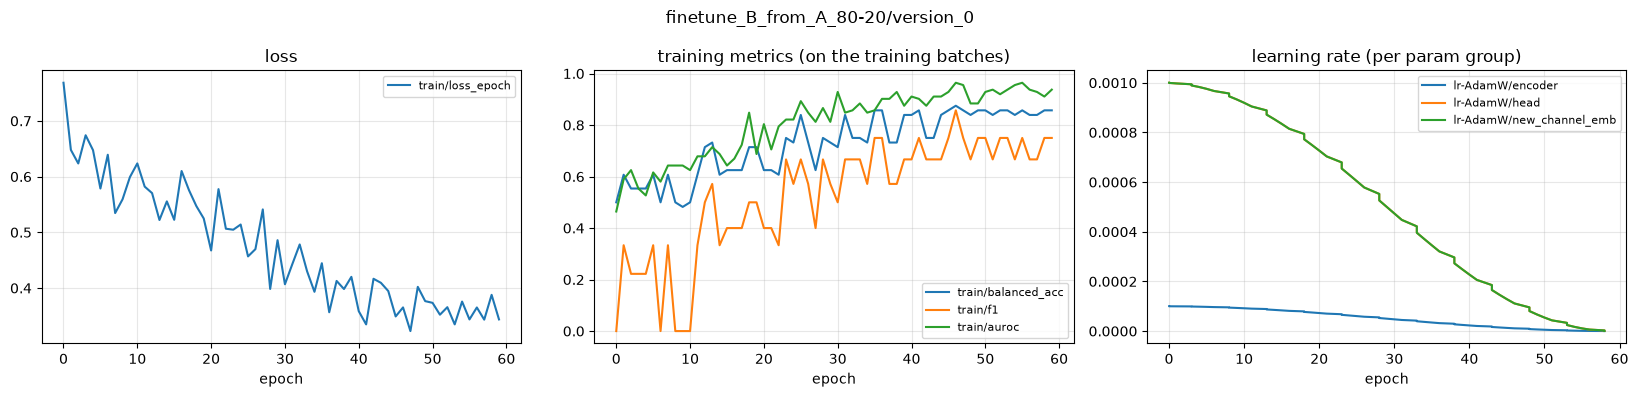

no validation set: trained 60 epochs, final weights tested


In [3]:
ft_scalars, ft_images = load_run(FINETUNE_RUN)
plot_scalars(ft_scalars, {
    "loss": ["train/loss_epoch", "val/loss"],
    "training metrics (on the training batches)": ["train/balanced_acc", "train/f1", "train/auroc"],
    "learning rate (per param group)": "lr-*",
}, FINETUNE_RUN)
if "val/loss" in ft_scalars:
    best = ft_scalars["val/loss"].sort_values("value").iloc[0]
    print(f"best val/loss = {best.value:.4f} at epoch {int(best.epoch)} (this checkpoint is used for the test set)")
else:
    print(f"no validation set: trained {int(ft_scalars['train/loss_epoch'].epoch.max()) + 1} epochs, final weights tested")

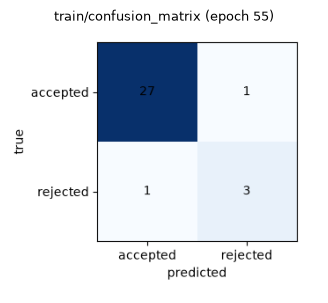

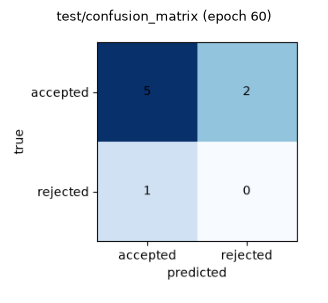

In [4]:
show_images(ft_images, "train/confusion_matrix", which="last", width=4)
show_images(ft_images, "test/confusion_matrix", which="last", width=4)

## Test results

,test (positive class = rejected)
acc,0.625
balanced_acc,0.357
precision,0.000
recall,0.000
f1,0.000
auroc,0.286


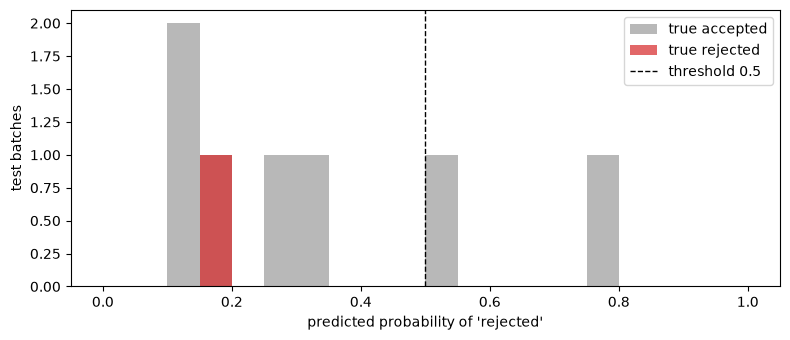

Misclassified test batches:


,batch_id,label,p_rejected,predicted
4,B_049,1,0.157861,0
7,B_077,0,0.535674,1
3,B_044,0,0.771284,1


In [5]:
run_dir = f"{LOGDIR}/{FINETUNE_RUN}"
if os.path.exists(f"{run_dir}/test_metrics.json"):
    metrics = json.load(open(f"{run_dir}/test_metrics.json"))
    display(pd.Series(metrics, name="test (positive class = rejected)").round(3).to_frame())
    preds = pd.read_csv(f"{run_dir}/test_predictions.csv")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for lab, name, c in [(0, "accepted", "#9a9a9a"), (1, "rejected", "#d62728")]:
        ax.hist(preds.p_rejected[preds.label == lab], bins=20, range=(0, 1), alpha=0.7, color=c, label=f"true {name}")
    ax.axvline(0.5, color="k", ls="--", lw=1, label="threshold 0.5")
    ax.set_xlabel("predicted probability of 'rejected'"); ax.set_ylabel("test batches"); ax.legend()
    plt.tight_layout(); plt.show()
    print("Misclassified test batches:")
    display(preds[preds.label != preds.predicted].sort_values("p_rejected"))
else:
    print("no test_metrics.json in", run_dir)

## Compare the process B runs

Test scores of every run that has a `test_metrics.json`, plus how many epochs it trained and which epoch was used. Positive class = rejected.

In [6]:
rows = []
for f in sorted(glob.glob(f"{LOGDIR}/finetune_B*/version_*/test_metrics.json")):
    run = os.path.relpath(os.path.dirname(f), LOGDIR)
    row = {"run": run, **json.load(open(f))}
    hp = open(os.path.join(os.path.dirname(f), "hparams.yaml")).read()
    row["encoder"] = "frozen" if "freeze_encoder: true" in hp else "finetuned"
    ld = [l.split(":", 1)[1].strip() for l in hp.splitlines() if l.startswith("layer_decay:")]
    row["layer_decay"] = ld[0] if ld and ld[0] != "null" else "-"
    row["augment"] = "augment:" in hp and "augment: null" not in hp
    row["pretrained"] = "pretrained_ckpt: null" not in hp
    sc, _ = load_run(run)
    row["epochs_trained"] = int(sc["train/loss_epoch"].epoch.max()) + 1
    tp = pd.read_csv(os.path.join(os.path.dirname(f), "test_predictions.csv"))
    row["test_batches"], row["test_rejected"] = len(tp), int(tp.label.sum())
    rows.append(row)
cols = ["run", "test_batches", "test_rejected", "epochs_trained",
        "f1", "precision", "recall", "balanced_acc", "acc", "auroc"]
comparison = pd.DataFrame(rows)[cols].set_index("run").round(3)
comparison

,test_batches,test_rejected,epochs_trained,f1,precision,recall,balanced_acc,acc,auroc
run,,,,,,,,,
finetune_B_from_A/version_0,20,2,20,0.0,0.0,0.0,0.472,0.850,0.556
finetune_B_from_A/version_1,20,2,60,0.0,0.0,0.0,0.472,0.850,0.639
finetune_B_from_A_80-20/version_0,8,1,60,0.0,0.0,0.0,0.357,0.625,0.286


* `finetune_B_from_A_80-20/version_0`: **current split (80/20)**. 60 epochs, no validation, new variable embeddings at the head learning rate (1e-3).
* `finetune_B_from_A/version_0` and `version_1` are earlier runs on the **old 50/50 split** (20 test batches, 2 rejected), so they used a different test set and are not directly comparable:
  * version_0: 20 epochs, new embeddings at the encoder learning rate (1e-4). It did not fit even the training data.
  * version_1: same settings as the current run.

## Reference: a one-feature rule

The process B EDA (`pca_process_B.ipynb`) found that rejected batches have a temporary drop in `aeration_rate`. As a sanity check for the deep model, here is the simplest possible classifier: the standard deviation of `aeration_rate` per batch, with the threshold set **on the training split only** (midway between the largest accepted and the smallest rejected value), then applied to the test split.

In [7]:
from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
def batch_feature(csv):
    d = pd.read_csv(csv)
    return d.groupby("batch_id").agg(aeration_std=("aeration_rate", "std"), label=("label", "first"))
tr, te = batch_feature("training_process_B.csv"), batch_feature("test_process_B.csv")
thr = (tr.aeration_std[tr.label == "accepted"].max() + tr.aeration_std[tr.label == "rejected"].min()) / 2
y, yp = (te.label == "rejected").astype(int), (te.aeration_std > thr).astype(int)
rule = {"acc": (y == yp).mean(), "balanced_acc": balanced_accuracy_score(y, yp),
        "precision": precision_score(y, yp, zero_division=0), "recall": recall_score(y, yp, zero_division=0),
        "f1": f1_score(y, yp, zero_division=0), "auroc": roc_auc_score(y, te.aeration_std)}
print(f"threshold (from training split) = {thr:.4f}")
pd.DataFrame({"rule: std(aeration_rate)": rule, f"deep model ({FINETUNE_RUN})": metrics}).round(3)

threshold (from training split) = 0.2812


,rule: std(aeration_rate),deep model (finetune_B_from_A_80-20/version_0)
acc,1.0,0.625
balanced_acc,1.0,0.357
precision,1.0,0.000
recall,1.0,0.000
f1,1.0,0.000
auroc,1.0,0.286
